## Instalación y dependencias

Este bloque es opcional y solo debe descomentarse si el entorno todavía no tiene las dependencias instaladas. El proyecto utiliza pandas y NumPy para manipulación de datos, matplotlib y seaborn para visualización, scikit-learn para los modelos clásicos y TensorFlow/Keras para el perceptrón multicapa.

La segunda línea permite regenerar `requirements.txt` a partir del entorno activo.


In [1]:
#%pip install pandas numpy matplotlib seaborn scikit-learn tensorflow jupyter ipykernel
#%pip freeze > requirements.txt

## 1. Configuración, carga y partición de datos

Este bloque prepara todo lo que compartirán los tres modelos:

- Fija la semilla `42` para que la partición y los resultados sean reproducibles.
- Configura el estilo de las visualizaciones.
- Carga el dataset de vino tinto desde una ruta local o desde UCI como alternativa.
- Crea la variable objetivo `seleccion`: vale `1` cuando `quality >= 7` y `0` en el resto.
- Separa las 11 variables fisicoquímicas de la calidad original para evitar utilizar la respuesta directamente como entrada.
- Divide los datos en `Train` (80 %) y `Test` (20 %) usando estratificación.

La estratificación es especialmente importante porque Selección es una clase minoritaria: mantiene una proporción similar en ambos subconjuntos y evita que la evaluación dependa de un reparto accidental.


In [2]:


import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 1. Fijar semillas globales para reproducibilidad total
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Configuración visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)

# 2. Carga de datos (ruta local con fallback a repositorio oficial UCI)
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
try:
    df = pd.read_csv("../data/winequality-red.csv", sep=";")
    print("Dataset cargado desde archivo local.")
except FileNotFoundError:
    df = pd.read_csv(URL_UCI, sep=";")
    print("Dataset cargado directamente desde UCI Repository.")

# 3. Definición de la variable objetivo: Selección (quality >= 7)
df["seleccion"] = (df["quality"] >= 7).astype(int)

print(f"Dimensiones totales: {df.shape[0]} lotes y {df.shape[1]-2} variables fisicoquímicas.")
print(f"Valores nulos totales: {df.isnull().sum().sum()}")

# 4. Partición Train / Test (80/20) estratificada con random_state=42
# Usamos stratify para mantener exactamente la misma proporción de vinos Selección (~13.6%)
X = df.drop(columns=["quality", "seleccion"])
y = df["seleccion"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"\nConjunto de Entrenamiento: {X_train.shape[0]} lotes ({y_train.mean()*100:.2f}% Selección)")
print(f"Conjunto de Prueba:        {X_test.shape[0]} lotes ({y_test.mean()*100:.2f}% Selección)")

Dataset cargado directamente desde UCI Repository.
Dimensiones totales: 1599 lotes y 11 variables fisicoquímicas.
Valores nulos totales: 0

Conjunto de Entrenamiento: 1279 lotes (13.60% Selección)
Conjunto de Prueba:        320 lotes (13.44% Selección)


### Lectura de la salida

El dataset contiene 1.599 lotes, 11 variables de entrada y ningún valor nulo. La clase Selección representa aproximadamente el 13,6 %. El conjunto de prueba queda fijado en 320 lotes y se utiliza únicamente para la comparación final.


## 2. Análisis exploratorio sobre Train

El EDA se realiza únicamente sobre el conjunto de entrenamiento para no filtrar información del test. Se estudian tres aspectos:

1. **Desbalanceo:** se cuentan los lotes Estándar y Selección.
2. **Asociación con la etiqueta:** la correlación de Pearson orienta qué variables pueden ser discriminantes; no demuestra causalidad.
3. **Distribuciones y valores atípicos:** los boxplots comparan las dos clases y la regla `1,5 × IQR` cuantifica outliers por variable.

Los resultados guían la construcción de McCulloch-Pitts y ayudan a interpretar los pesos del Perceptrón, pero no se utilizan para eliminar automáticamente observaciones.


Distribución de clases en Train:
 - Estándar (0):  1105 lotes (86.40%)
 - Selección (1): 174 lotes (13.60%)

Correlación de Pearson con 'Selección' (en Train):
alcohol                 0.402
citric acid             0.206
sulphates               0.185
fixed acidity           0.111
residual sugar          0.044
pH                     -0.055
free sulfur dioxide    -0.076
chlorides              -0.090
density                -0.150
total sulfur dioxide   -0.163
volatile acidity       -0.260
Name: seleccion, dtype: float64


/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_82234/2317316294.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_82234/2317316294.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_82234/2317316294.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_82234/2317316294.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fi

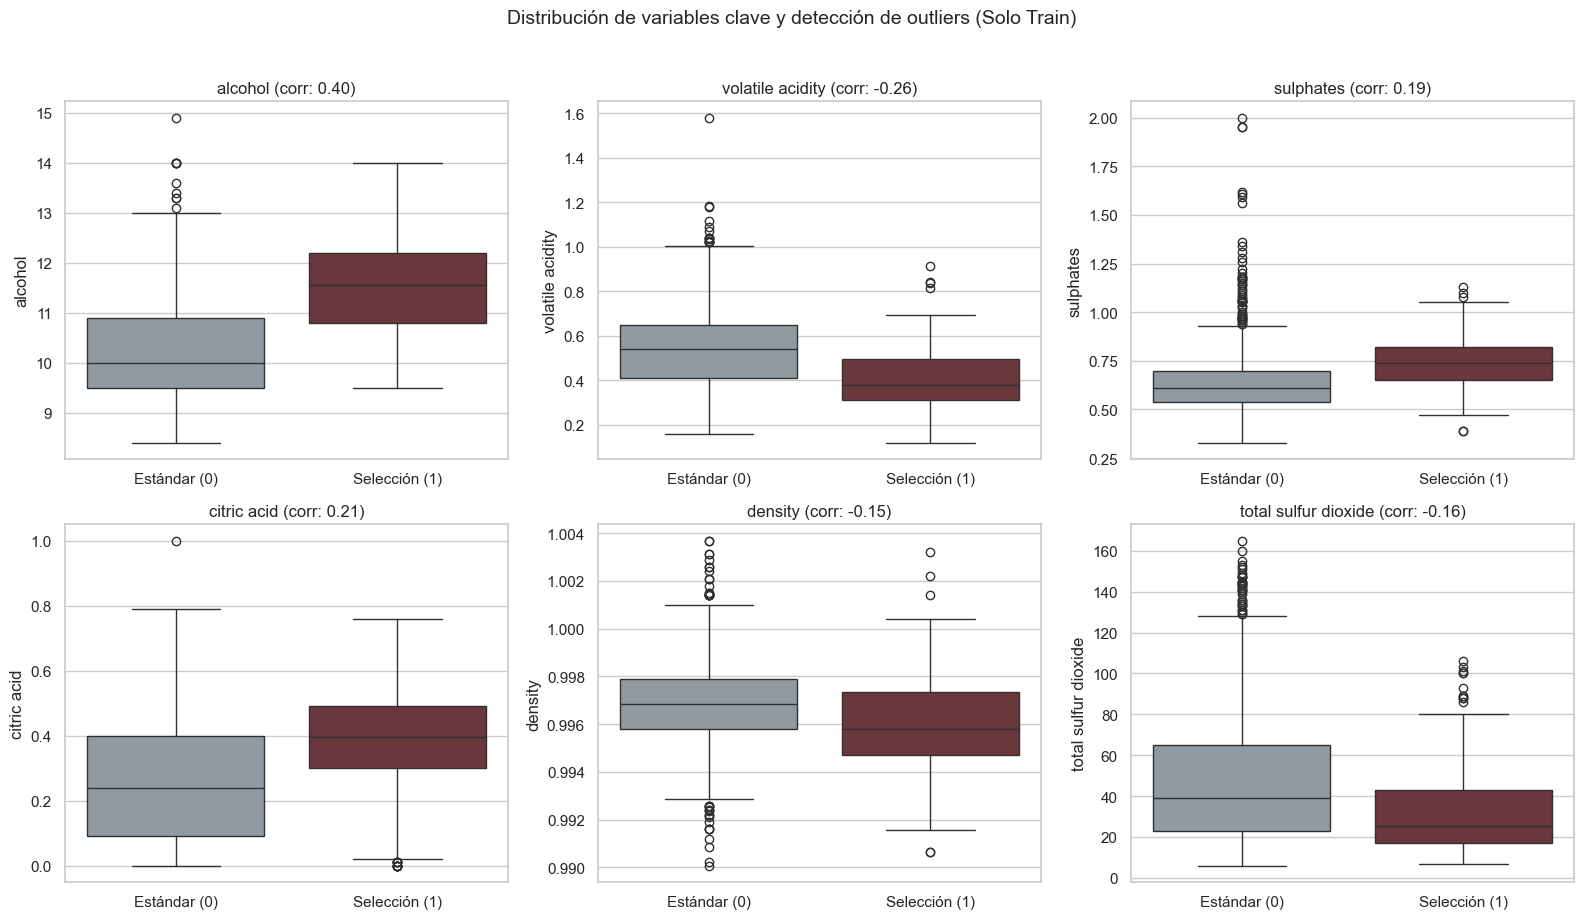


Porcentaje de valores atípicos (outliers) por variable en Train:
residual sugar          9.54
chlorides               6.33
sulphates               3.75
total sulfur dioxide    3.52
density                 3.05
fixed acidity           2.03
pH                      2.03
free sulfur dioxide     1.88
volatile acidity        1.17
alcohol                 0.94
citric acid             0.08
dtype: float64


In [3]:
# ==============================================================================
# EDA (Exclusivamente sobre el conjunto de entrenamiento)
# ==============================================================================

train_df = X_train.copy()
train_df["seleccion"] = y_train

# 1. Análisis de desbalanceo de clases
conteo = train_df["seleccion"].value_counts()
print("Distribución de clases en Train:")
print(f" - Estándar (0):  {conteo[0]} lotes ({conteo[0]/len(train_df)*100:.2f}%)")
print(f" - Selección (1): {conteo[1]} lotes ({conteo[1]/len(train_df)*100:.2f}%)")

# 2. Correlación de cada parámetro con la etiqueta Selección
correlaciones = train_df.corr()["seleccion"].drop("seleccion").sort_values(ascending=False)
print("\nCorrelación de Pearson con 'Selección' (en Train):")
print(correlaciones.round(3))

# 3. Visualización: Comparativa de las variables más discriminantes y Outliers
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
top_vars = ["alcohol", "volatile acidity", "sulphates", "citric acid", "density", "total sulfur dioxide"]

for ax, col in zip(axes.flat, top_vars):
    sns.boxplot(
        data=train_df, x="seleccion", y=col, ax=ax,
        hue="seleccion", palette=["#8c9ba5", "#722f37"], legend=False
    )
    ax.set_title(f"{col} (corr: {correlaciones[col]:.2f})")
    ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
    ax.set_xlabel("")

plt.suptitle("Distribución de variables clave y detección de outliers (Solo Train)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 4. Cuantificación de outliers (regla 1.5 * IQR en Train)
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
outliers_pct = ((X_train < (Q1 - 1.5 * IQR)) | (X_train > (Q3 + 1.5 * IQR))).mean() * 100
print("\nPorcentaje de valores atípicos (outliers) por variable en Train:")
print(outliers_pct.sort_values(ascending=False).round(2))

### Lectura de la salida

La distribución confirma el desbalanceo. Las correlaciones positivas más destacadas en Train son alcohol (`0,402`), citric acid (`0,206`) y sulphates (`0,185`); las negativas más destacadas son volatile acidity (`-0,260`) y total sulfur dioxide (`-0,163`). Estas asociaciones justifican la dirección de las reglas de McCulloch-Pitts, pero no sustituyen la evaluación del modelo.


## 3. Criterio común de evaluación técnica y económica

Para que los modelos sean comparables, todos pasan por `evaluar_modelo`. La función calcula accuracy, precisión y recall de la clase Selección, además de la matriz de confusión.

La parte económica traduce los errores a una proyección de 1.600 lotes/año:

- Un verdadero positivo aporta 1.200 € de sobreprecio.
- Un falso positivo cuesta 2.500 € por riesgo de marca y devoluciones.
- Un falso negativo representa 1.200 € de oportunidad no capturada.

El beneficio neto usado para seleccionar umbrales es `VP × 1.200 − FP × 2.500`. La prueba final se mantiene separada y solo se utiliza después de fijar las decisiones en Train.


In [4]:
# ==============================================================================
# FUNCIÓN COMÚN DE EVALUACIÓN TÉCNICA Y DE NEGOCIO
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Supuestos económicos del cliente (Celler del Túria)
LOTES_ANUALES = 1600
FACTOR_ESCALA = LOTES_ANUALES / len(y_test)  # ~5.0 (1600 / 320)
SOBREPRECIO_SELECCION = 1200  # +40% sobre 3.000 € por lote correcto (VP)
COSTE_FALSO_POSITIVO = 2500   # Vino mediocre etiquetado como Selección (FP)

resultados_modelos = []

def evaluar_modelo(nombre_modelo, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    
    # Matriz de confusión: [[VN, FP], [FN, VP]]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    # Escalado anual (de ~320 lotes de test a 1.600 lotes/año)
    tp_anual = round(tp * FACTOR_ESCALA)
    fp_anual = round(fp * FACTOR_ESCALA)
    fn_anual = round(fn * FACTOR_ESCALA)
    tn_anual = round(tn * FACTOR_ESCALA)
    
    # Impacto económico neto anual:
    # Ganamos +1.200€ por cada Selección real detectado (VP)
    # Perdemos -2.500€ por cada mediocre colado como Selección (FP)
    # (Los FN no restan caja directa, son coste de oportunidad = fn_anual * 1200€)
    ingresos_extra = tp_anual * SOBREPRECIO_SELECCION
    perdidas_marca = fp_anual * COSTE_FALSO_POSITIVO
    beneficio_neto = ingresos_extra - perdidas_marca
    coste_oportunidad = fn_anual * SOBREPRECIO_SELECCION
    
    print(f"\n{'='*60}")
    print(f"RESULTADOS: {nombre_modelo}")
    print(f"{'='*60}")
    print(f"Accuracy:  {acc*100:.2f}% | Precisión (Selección): {prec*100:.2f}% | Recall (Selección): {rec*100:.2f}%")
    print(f"\nMatriz de Confusión (Test - {len(y_true)} lotes):")
    print(f"  Verdaderos Negativos (Estándar OK):  {tn:3d} | Falsos Positivos (ERROR CARO): {fp:3d}")
    print(f"  Falsos Negativos (Oportunidad perd.): {fn:3d} | Verdaderos Positivos (Sel. OK):  {tp:3d}")
    print(f"\nProyección Anual ({LOTES_ANUALES} lotes/año):")
    print(f"  - Lotes Selección bien detectados: {tp_anual} lotes  --> +{ingresos_extra:,.0f} €")
    print(f"  - Lotes mediocres colados (FP):    {fp_anual} lotes  --> -{perdidas_marca:,.0f} €")
    print(f"  - Lotes buenos perdidos (FN):       {fn_anual} lotes  --> ({coste_oportunidad:,.0f} € no capturados)")
    print(f"  >>> IMPACTO NETO ANUAL ESTIMADO:    {beneficio_neto:+,.0f} € / año")
    
    resultados_modelos.append({
        "Modelo": nombre_modelo,
        "Accuracy (%)": round(acc * 100, 2),
        "Precisión (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "VP_anual": tp_anual,
        "FP_anual": fp_anual,
        "FN_anual": fn_anual,
        "Beneficio_Neto_EUR": beneficio_neto
    })

### Lectura de la salida

La función no elige el modelo por una sola métrica. Penaliza especialmente los falsos positivos porque su coste unitario es mayor. Por eso un modelo con accuracy alta puede no ser la alternativa más rentable si etiqueta demasiados lotes mediocres como Selección.


## 4. Modelo 1: neurona de McCulloch-Pitts

Esta es la aproximación más interpretable. Las variables se convierten en entradas binarias:

- En variables positivas, `1` significa que el valor está por encima de la mediana de Selección calculada en Train.
- En variables negativas, `1` significa que está por debajo de esa mediana.

La neurona suma las condiciones cumplidas y se activa cuando la suma alcanza `theta`. El umbral se busca en Train maximizando el beneficio económico, y solo después se evalúa en Test.

La ventaja es que la regla se puede explicar fácilmente; la limitación es que pierde la distancia real entre valores y trata todas las condiciones con el mismo peso.


In [18]:
# ==============================================================================
# MODELO 1: NEURONA DE McCULLOCH-PITTS (1943)
# ==============================================================================

# 1. Selección de variables discriminantes (basadas en correlaciones del EDA en Train)
# Distinguimos variables positivas (más es mejor) y negativas (menos es mejor)
vars_positivas = ["alcohol", "sulphates", "citric acid", "fixed acidity"]
vars_negativas = ["volatile acidity", "density", "total sulfur dioxide", "chlorides"]
vars_mp = vars_positivas + vars_negativas

# 2. Cálculo de umbrales de binarización (SOLO sobre X_train)
# Usamos la mediana de los vinos Selección en Train como referencia de "perfil óptimo"
umbrales_mp = {}
for col in vars_positivas:
    umbrales_mp[col] = X_train.loc[y_train == 1, col].median()
for col in vars_negativas:
    umbrales_mp[col] = X_train.loc[y_train == 1, col].median()

def binarizar_mp(df_in):
    bin_df = pd.DataFrame(index=df_in.index)
    for col in vars_positivas:
        bin_df[col] = (df_in[col] >= umbrales_mp[col]).astype(int)
    for col in vars_negativas:
        # 1 si está por debajo o igual al umbral (ej. baja acidez volátil = bueno)
        bin_df[col] = (df_in[col] <= umbrales_mp[col]).astype(int)
    return bin_df

X_train_bin = binarizar_mp(X_train)
X_test_bin = binarizar_mp(X_test)

# 3. Búsqueda del umbral de disparo (theta) óptimo en TRAIN según criterio de negocio
# La neurona M-P suma las entradas binarias: y = 1 si sum(x_i) >= theta
mejor_theta = None
mejor_beneficio_train = -np.inf

for theta in range(1, len(vars_mp) + 1):
    pred_tr = (X_train_bin.sum(axis=1) >= theta).astype(int)
    tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_train, pred_tr).ravel()
    # Calculamos beneficio neto en train para elegir el theta más rentable
    beneficio_tr = (tp_tr * SOBREPRECIO_SELECCION) - (fp_tr * COSTE_FALSO_POSITIVO)
    print(f"Theta = {theta}/{len(vars_mp)} -> Train VP: {tp_tr:3d}, FP: {fp_tr:3d} | Beneficio Train: {beneficio_tr:+9,.0f} €")
    if beneficio_tr > mejor_beneficio_train:
        mejor_beneficio_train = beneficio_tr
        mejor_theta = theta

print(f"\nUmbral de disparo elegido (optimizado en Train): theta = {mejor_theta} de {len(vars_mp)} condiciones")

# 4. Evaluación final en TEST
y_pred_mp = (X_test_bin.sum(axis=1) >= mejor_theta).astype(int)
evaluar_modelo("1. Neurona McCulloch-Pitts (1943)", y_test, y_pred_mp)

Theta = 1/8 -> Train VP: 172, FP: 883 | Beneficio Train: -2,001,100 €
Theta = 2/8 -> Train VP: 163, FP: 595 | Beneficio Train: -1,291,900 €
Theta = 3/8 -> Train VP: 142, FP: 366 | Beneficio Train:  -744,600 €
Theta = 4/8 -> Train VP: 119, FP: 194 | Beneficio Train:  -342,200 €
Theta = 5/8 -> Train VP:  68, FP:  78 | Beneficio Train:  -113,400 €
Theta = 6/8 -> Train VP:  33, FP:  22 | Beneficio Train:   -15,400 €
Theta = 7/8 -> Train VP:   9, FP:   2 | Beneficio Train:    +5,800 €
Theta = 8/8 -> Train VP:   0, FP:   0 | Beneficio Train:        +0 €

Umbral de disparo elegido (optimizado en Train): theta = 7 de 8 condiciones

RESULTADOS: 1. Neurona McCulloch-Pitts (1943)
Accuracy:  88.12% | Precisión (Selección): 100.00% | Recall (Selección): 11.63%

Matriz de Confusión (Test - 320 lotes):
  Verdaderos Negativos (Estándar OK):  277 | Falsos Positivos (ERROR CARO):   0
  Falsos Negativos (Oportunidad perd.):  38 | Verdaderos Positivos (Sel. OK):    5

Proyección Anual (1600 lotes/año):
  

### Resultado de McCulloch-Pitts

En la ejecución actual se selecciona `theta = 7` de 8 condiciones. En Test alcanza 88,12 % de accuracy, 100,00 % de precisión y 11,63 % de recall. Proyectado a 1.600 lotes, obtiene 25 verdaderos positivos, 0 falsos positivos y un beneficio neto estimado de **+30.000 €/año**. Es una opción muy conservadora: protege la marca, pero deja escapar muchos lotes buenos.


## 5. Modelo 2: Perceptrón Simple

El Perceptrón conserva las variables continuas, pero las estandariza con media cero y desviación típica uno. El `StandardScaler` se ajusta solo con `X_train` y después transforma `X_test`, evitando fuga de información.

Durante el entrenamiento aprende un peso por variable y un sesgo. La función interna es `z = w · x + b`; sus pesos permiten contrastar lo aprendido con las correlaciones del EDA.

Se utiliza `class_weight="balanced"` para dar más importancia a la clase Selección. Finalmente, el umbral de `z` se calibra en Train con el mismo criterio de beneficio.


Comparativa de Pesos del Perceptrón vs Correlación del EDA:
            Variable  Peso_Perceptron  Corr_EDA
       fixed acidity         0.051948  0.110706
             alcohol         0.037183  0.401582
         citric acid         0.035862  0.205532
           sulphates         0.012668  0.185007
      residual sugar         0.004427  0.044116
 free sulfur dioxide        -0.005884 -0.075589
             density        -0.012392 -0.150213
                  pH        -0.036643 -0.054883
           chlorides        -0.046925 -0.089887
total sulfur dioxide        -0.060749 -0.163241
    volatile acidity        -0.081582 -0.260279


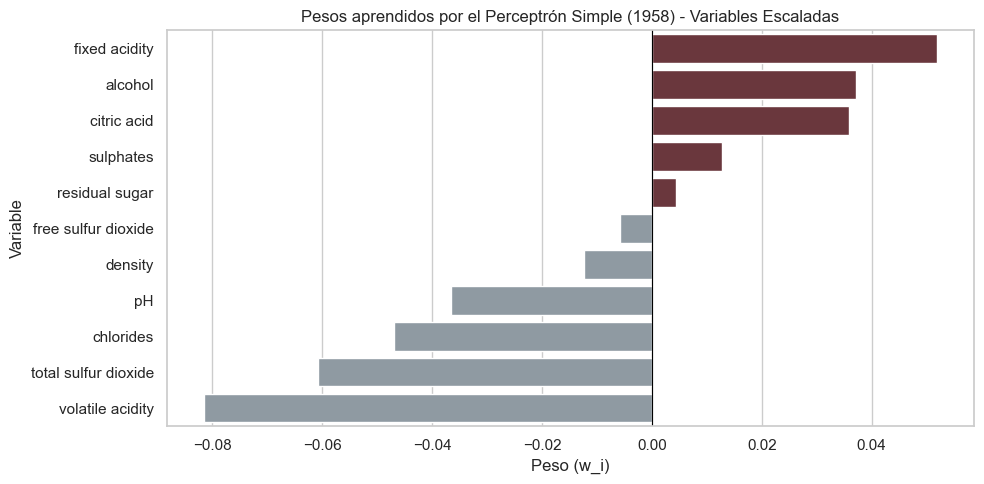


Umbral de decisión óptimo encontrado en Train: z >= 0.3489

RESULTADOS: 2. Perceptrón Simple (1958)
Accuracy:  86.25% | Precisión (Selección): 40.00% | Recall (Selección): 4.65%

Matriz de Confusión (Test - 320 lotes):
  Verdaderos Negativos (Estándar OK):  274 | Falsos Positivos (ERROR CARO):   3
  Falsos Negativos (Oportunidad perd.):  41 | Verdaderos Positivos (Sel. OK):    2

Proyección Anual (1600 lotes/año):
  - Lotes Selección bien detectados: 10 lotes  --> +12,000 €
  - Lotes mediocres colados (FP):    15 lotes  --> -37,500 €
  - Lotes buenos perdidos (FN):       205 lotes  --> (246,000 € no capturados)
  >>> IMPACTO NETO ANUAL ESTIMADO:    -25,500 € / año


/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered 

In [16]:
# ==============================================================================
# MODELO 2: PERCEPTRÓN SIMPLE (1958)
# ==============================================================================
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron

# 1. Escalado de variables reales (ajustado SOLO con X_train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Entrenamiento del Perceptrón (con semilla fija y balanceo de clases)
# class_weight='balanced' evita que ignore la clase minoritaria (13.6%)
perceptron = Perceptron(
    max_iter=1000,
    tol=1e-4,
    random_state=SEED,
    class_weight="balanced",
    eta0=0.01
)
perceptron.fit(X_train_scaled, y_train)

# 3. Interpretación de pesos aprendidos vs Análisis Previo (EDA)
pesos_df = pd.DataFrame({
    "Variable": X_train.columns,
    "Peso_Perceptron": perceptron.coef_[0],
    "Corr_EDA": [correlaciones[col] for col in X_train.columns]
}).sort_values(by="Peso_Perceptron", ascending=False)

print("Comparativa de Pesos del Perceptrón vs Correlación del EDA:")
print(pesos_df.to_string(index=False))

# Visualización rápida de los pesos
plt.figure(figsize=(10, 5))
colores = ["#722f37" if w > 0 else "#8c9ba5" for w in pesos_df["Peso_Perceptron"]]
sns.barplot(data=pesos_df, x="Peso_Perceptron", y="Variable", palette=colores, hue="Variable", legend=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Pesos aprendidos por el Perceptrón Simple (1958) - Variables Escaladas")
plt.xlabel("Peso (w_i)")
plt.tight_layout()
plt.show()

# 4. Ajuste del umbral de decisión (z >= umbral) en TRAIN según costes del negocio
# decision_function devuelve z = w*x + b
z_train = perceptron.decision_function(X_train_scaled)
z_test = perceptron.decision_function(X_test_scaled)

umbrales_z = np.linspace(z_train.min(), z_train.max(), 200)
mejor_z = 0.0
mejor_ben_p = -np.inf

for u in umbrales_z:
    pred_tr = (z_train >= u).astype(int)
    tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_train, pred_tr).ravel()
    ben_tr = (tp_tr * SOBREPRECIO_SELECCION) - (fp_tr * COSTE_FALSO_POSITIVO)
    if ben_tr > mejor_ben_p:
        mejor_ben_p = ben_tr
        mejor_z = u

print(f"\nUmbral de decisión óptimo encontrado en Train: z >= {mejor_z:.4f}")

# 5. Evaluación en TEST (con umbral ajustado a negocio)
y_pred_perc = (z_test >= mejor_z).astype(int)
evaluar_modelo("2. Perceptrón Simple (1958)", y_test, y_pred_perc)

### Resultado del Perceptrón Simple

Con el umbral de decisión calibrado en Train, el Perceptrón obtiene 86,25 % de accuracy, 40,00 % de precisión y 4,65 % de recall. La proyección anual es de 10 verdaderos positivos y 15 falsos positivos, lo que produce un beneficio neto estimado de **-25.500 €/año**. En este escenario no compensa el riesgo económico de sus falsos positivos.


## 6. Modelo 3: Perceptrón Multicapa (MLP)

El MLP añade capas densas y activaciones no lineales `ReLU`, por lo que puede aprender relaciones que una frontera lineal no representa. La salida `sigmoid` devuelve una probabilidad de Selección.

Se comparan tres arquitecturas: una capa de 16 unidades, dos capas `32-16` y tres capas `64-32-16`. Los pesos de clase compensan el desbalanceo; Dropout, regularización L2 y `EarlyStopping` ayudan a controlar el sobreajuste.

La arquitectura ganadora se elige con la pérdida de validación interna de Train. Después se calibra el umbral de probabilidad en Train y se reserva Test para la evaluación final.


/Users/ivanb/VisualStudio/pia-bodegaVinos/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Entrenando y comparando arquitecturas MLP (validación interna sobre Train)...

 - Arq A: Simple (16) sin reg.              | Mejor val_loss: 0.4076 (parada en época 150)
 - Arq B: Media (32-16) + Dropout/L2        | Mejor val_loss: 0.4284 (parada en época 133)
 - Arq C: Profunda (64-32-16) + Dropout/L2  | Mejor val_loss: 0.4299 (parada en época 126)

>>> Arquitectura ganadora seleccionada: Arq A: Simple (16) sin reg.


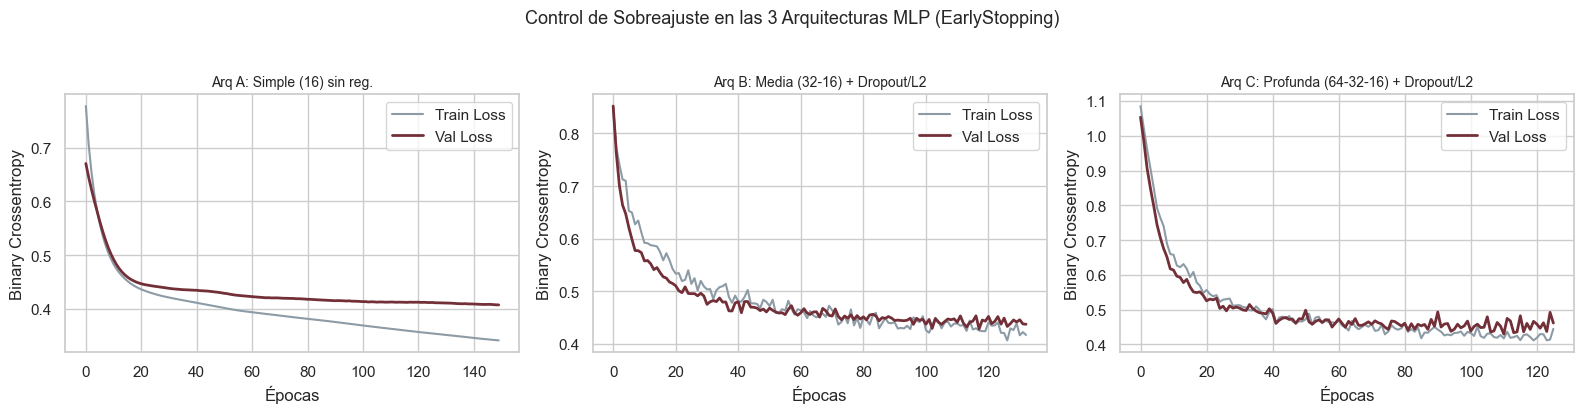


Umbral de probabilidad óptimo (calibrado en Train por costes): p >= 0.89

RESULTADOS: 3. Perceptrón Multicapa (Arq A)
Accuracy:  90.00% | Precisión (Selección): 78.95% | Recall (Selección): 34.88%

Matriz de Confusión (Test - 320 lotes):
  Verdaderos Negativos (Estándar OK):  273 | Falsos Positivos (ERROR CARO):   4
  Falsos Negativos (Oportunidad perd.):  28 | Verdaderos Positivos (Sel. OK):   15

Proyección Anual (1600 lotes/año):
  - Lotes Selección bien detectados: 75 lotes  --> +90,000 €
  - Lotes mediocres colados (FP):    20 lotes  --> -50,000 €
  - Lotes buenos perdidos (FN):       140 lotes  --> (168,000 € no capturados)
  >>> IMPACTO NETO ANUAL ESTIMADO:    +40,000 € / año


In [7]:
# ==============================================================================
# MODELO 3: PERCEPTRÓN MULTICAPA (MLP) CON KERAS
# ==============================================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.utils.class_weight import compute_class_weight

# Fijar semilla de TensorFlow/Keras
tf.random.set_seed(SEED)

# Calcular pesos de clase en Train para compensar el desbalanceo (86% vs 14%)
pesos_clases = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {0: pesos_clases[0], 1: pesos_clases[1]}

def construir_mlp(capas, dropout_rate=0.0, l2_reg=0.0):
    tf.random.set_seed(SEED)
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train_scaled.shape[1],)))
    for units in capas:
        model.add(layers.Dense(
            units,
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_reg) if l2_reg > 0 else None
        ))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate, seed=SEED))
    model.add(layers.Dense(1, activation="sigmoid"))
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]
    )
    return model

# Definición de las 3 arquitecturas a comparar
arquitecturas = {
    "Arq A: Simple (16) sin reg.": {"capas": [16], "dropout": 0.0, "l2": 0.0},
    "Arq B: Media (32-16) + Dropout/L2": {"capas": [32, 16], "dropout": 0.3, "l2": 0.005},
    "Arq C: Profunda (64-32-16) + Dropout/L2": {"capas": [64, 32, 16], "dropout": 0.3, "l2": 0.005}
}

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

modelos_entrenados = {}
historiales = {}
mejor_val_loss = np.inf
mejor_nombre_arq = None

print("Entrenando y comparando arquitecturas MLP (validación interna sobre Train)...\n")
for nombre, cfg in arquitecturas.items():
    modelo = construir_mlp(cfg["capas"], cfg["dropout"], cfg["l2"])
    hist = modelo.fit(
        X_train_scaled, y_train,
        epochs=150,
        batch_size=32,
        validation_split=0.2,
        class_weight=class_weight_dict,
        callbacks=[early_stop],
        verbose=0
    )
    val_loss_min = min(hist.history["val_loss"])
    epochs_real = len(hist.history["loss"])
    print(f" - {nombre:<40} | Mejor val_loss: {val_loss_min:.4f} (parada en época {epochs_real})")
    
    modelos_entrenados[nombre] = modelo
    historiales[nombre] = hist
    if val_loss_min < mejor_val_loss:
        mejor_val_loss = val_loss_min
        mejor_nombre_arq = nombre

print(f"\n>>> Arquitectura ganadora seleccionada: {mejor_nombre_arq}")
mejor_mlp = modelos_entrenados[mejor_nombre_arq]

# Gráfica de control de sobreajuste (Train vs Val Loss)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nombre, hist) in zip(axes, historiales.items()):
    ax.plot(hist.history["loss"], label="Train Loss", color="#8c9ba5")
    ax.plot(hist.history["val_loss"], label="Val Loss", color="#722f37", linewidth=2)
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Binary Crossentropy")
    ax.legend()
plt.suptitle("Control de Sobreajuste en las 3 Arquitecturas MLP (EarlyStopping)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

# Ajuste de umbral de probabilidad (0 a 1) en TRAIN maximizando beneficio neto
probs_train = mejor_mlp.predict(X_train_scaled, verbose=0).ravel()
probs_test = mejor_mlp.predict(X_test_scaled, verbose=0).ravel()

umbrales_prob = np.linspace(0.30, 0.95, 131)
mejor_tau = 0.5
mejor_ben_mlp = -np.inf

for tau in umbrales_prob:
    pred_tr = (probs_train >= tau).astype(int)
    tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_train, pred_tr).ravel()
    ben_tr = (tp_tr * SOBREPRECIO_SELECCION) - (fp_tr * COSTE_FALSO_POSITIVO)
    if ben_tr > mejor_ben_mlp:
        mejor_ben_mlp = ben_tr
        mejor_tau = tau

print(f"\nUmbral de probabilidad óptimo (calibrado en Train por costes): p >= {mejor_tau:.2f}")

# Evaluación final en TEST
y_pred_mlp = (probs_test >= mejor_tau).astype(int)
evaluar_modelo(f"3. Perceptrón Multicapa ({mejor_nombre_arq.split(':')[0]})", y_test, y_pred_mlp)

### Resultado del MLP

La arquitectura ganadora es `Arq A: Simple (16) sin reg.`. El umbral de probabilidad se calibra en `p >= 0,89`. En Test obtiene 90,00 % de accuracy, 78,95 % de precisión y 34,88 % de recall. La proyección anual es de 75 verdaderos positivos y 20 falsos positivos: 90.000 € de ingresos extra menos 50.000 € de pérdidas, es decir, **+40.000 €/año** de beneficio neto estimado. Es la mejor alternativa de las tres, aunque debe validarse con datos propios.


## 7. Comparativa final para dirección

Esta última celda reúne los resultados de `evaluar_modelo` en una tabla y genera una gráfica ejecutiva. Las barras comparan los verdaderos positivos y falsos positivos proyectados a un año; la línea muestra el beneficio neto anual.

La visualización debe leerse junto con precisión y recall: un modelo puede acertar muchos casos Estándar y aun así detectar pocos vinos Selección. La recomendación del proyecto es usar el MLP como filtro previo supervisado y mantener la decisión final en el panel de cata.



TABLA RESUMEN COMPARATIVA (PROYECCIÓN ANUAL A 1.600 LOTES):
                           Modelo  Accuracy (%)  Precisión (%)  Recall (%)  VP_anual  FP_anual  FN_anual  Beneficio_Neto_EUR
1. Neurona McCulloch-Pitts (1943)         88.12         100.00       11.63        25         0       190               30000
      2. Perceptrón Simple (1958)         86.25          40.00        4.65        10        15       205              -25500
  3. Perceptrón Multicapa (Arq A)         90.00          78.95       34.88        75        20       140               40000


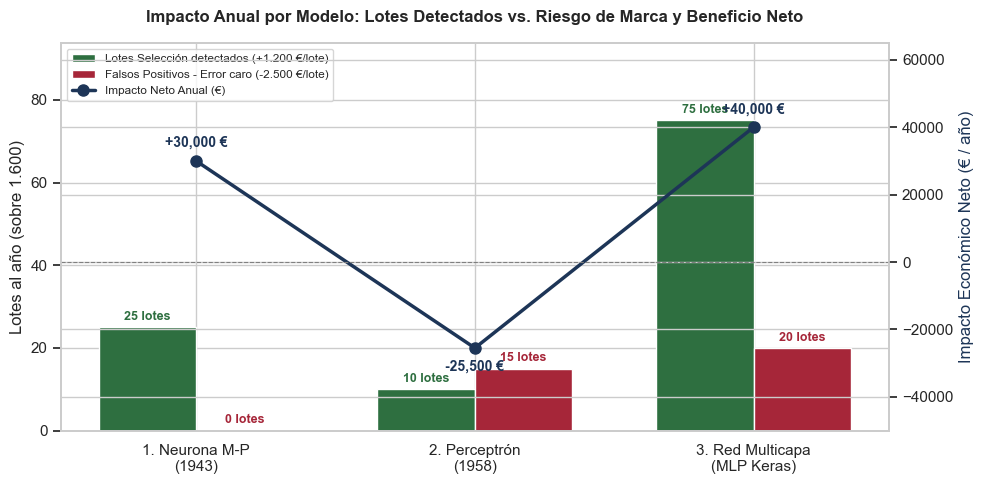

In [8]:
# ==============================================================================
# FASE FINAL DEL NOTEBOOK: TABLA COMPARATIVA Y GRÁFICA PARA DIRECCIÓN
# ==============================================================================

df_comparativa = pd.DataFrame(resultados_modelos)
print("\nTABLA RESUMEN COMPARATIVA (PROYECCIÓN ANUAL A 1.600 LOTES):")
print(df_comparativa.to_string(index=False))

# Gráfica ejecutiva (1 sola gráfica clara para el informe PDF de dirección)
fig, ax1 = plt.subplots(figsize=(10, 5))

modelos_nombres = ["1. Neurona M-P\n(1943)", "2. Perceptrón\n(1958)", "3. Red Multicapa\n(MLP Keras)"]
x = np.arange(len(modelos_nombres))
ancho = 0.35

# Barras: Lotes Selección acertados (VP) vs Lotes mediocres colados (FP)
rects1 = ax1.bar(x - ancho/2, df_comparativa["VP_anual"], ancho, label="Lotes Selección detectados (+1.200 €/lote)", color="#2e6f40")
rects2 = ax1.bar(x + ancho/2, df_comparativa["FP_anual"], ancho, label="Falsos Positivos - Error caro (-2.500 €/lote)", color="#a62639")

ax1.set_ylabel("Lotes al año (sobre 1.600)")
ax1.set_title("Impacto Anual por Modelo: Lotes Detectados vs. Riesgo de Marca y Beneficio Neto", fontsize=12, fontweight="bold", pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(modelos_nombres)
ax1.set_ylim(0, max(df_comparativa["VP_anual"]) * 1.25)

# Etiquetas sobre las barras
for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f"{h} lotes", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#2e6f40")
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f"{h} lotes", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#a62639")

# Eje secundario: Beneficio Neto Anual (€)
ax2 = ax1.twinx()
beneficios = df_comparativa["Beneficio_Neto_EUR"]
ax2.plot(x, beneficios, color="#1d3557", marker="o", linewidth=2.5, markersize=8, label="Impacto Neto Anual (€)")
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax2.set_ylabel("Impacto Económico Neto (€ / año)", color="#1d3557")
ax2.set_ylim(-50000, 65000)

for i, txt in enumerate(beneficios):
    offset_y = 10 if txt >= 0 else -16
    ax2.annotate(f"{txt:+,.0f} €", (x[i], beneficios[i]), textcoords="offset points",
                 xytext=(0, offset_y), ha="center", fontweight="bold", fontsize=10, color="#1d3557")

# Combinar leyendas
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

### Conclusión de la comparativa

El MLP ofrece el mayor beneficio neto estimado (+40.000 €/año) y el mejor equilibrio entre precisión y recall. McCulloch-Pitts también es rentable (+30.000 €/año), pero resulta demasiado conservadora. El Perceptrón Simple presenta un resultado negativo (-25.500 €/año) bajo los supuestos actuales. Estos importes no incluyen integración, mantenimiento ni validación de campo.
